In [6]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
from src.db import DATA_RAW, MODELS_DIR
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from catboost import CatBoostRegressor, Pool

df = pd.read_parquet(DATA_RAW / "cars.parquet")
print("shape:", df.shape)

# ── фичи ──────────────────────────────────────────────────────────────
target = "price"

# числовые
num_features = [
    "car_age", "mileage_km", "mileage_per_year", "power_hp",
    "engine_volume_l", "owners_count", "photos_count",
    "seller_age_years", "year",
]

# булевы
bool_features = df.select_dtypes(include="bool").columns.tolist()

# категориальные
cat_features = [
    "brand", "model", "generation", "fuel", "transmission",
    "drive", "color", "wheel", "seller_type", "city", "region",
]

features = num_features + bool_features + cat_features
# убрать дубликаты, если есть
features = list(dict.fromkeys(features))

# оставить только те, что реально есть
features = [f for f in features if f in df.columns]
cat_features = [f for f in cat_features if f in df.columns]

print(f"features: {len(features)} (num={len(num_features)}, "
      f"bool={len(bool_features)}, cat={len(cat_features)})")

# ── таргет в log ──────────────────────────────────────────────────────
df = df.dropna(subset=[target]).copy()
y = np.log1p(df[target])
X = df[features]

# ── split ─────────────────────────────────────────────────────────────
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ── CatBoost ──────────────────────────────────────────────────────────
model = CatBoostRegressor(
    iterations=3000,
    learning_rate=0.05,
    depth=8,
    l2_leaf_reg=3.0,
    cat_features=cat_features,
    random_seed=42,
    verbose=200,
    early_stopping_rounds=150,
    eval_metric="MAE",
)

model.fit(
    X_tr, y_tr,
    eval_set=(X_te, y_te),
    use_best_model=True,
)

# ── метрики ───────────────────────────────────────────────────────────
pred_log = model.predict(X_te)
pred_rub = np.expm1(pred_log)
y_te_rub = np.expm1(y_te)

mae_log = mean_absolute_error(y_te, pred_log)
r2_log = r2_score(y_te, pred_log)
mae_rub = mean_absolute_error(y_te_rub, pred_rub)
rmse_rub = np.sqrt(((y_te_rub - pred_rub) ** 2).mean())
mape = np.mean(np.abs((y_te_rub - pred_rub) / y_te_rub)) * 100

print(f"\n─── CatBoost ───")
print(f"MAE (log)  : {mae_log:.4f}")
print(f"R²  (log)  : {r2_log:.4f}")
print(f"MAE (руб)  : {mae_rub:,.0f}")
print(f"RMSE (руб) : {rmse_rub:,.0f}")
print(f"MAPE       : {mape:.2f}%")

# ── feature importance ────────────────────────────────────────────────
imp = pd.DataFrame({
    "feature": features,
    "importance": model.get_feature_importance(),
}).sort_values("importance", ascending=False)

print("\nТоп-25 фич:")
print(imp.head(25).to_string(index=False))

# ── сохранить модель ──────────────────────────────────────────────────
model.save_model(MODELS_DIR / "catboost_v1.cbm")
print(f"\n[model saved] {MODELS_DIR / 'catboost_v1.cbm'}")

# ── сохранить предсказания для анализа ────────────────────────────────
pred_df = pd.DataFrame({
    "y_true_log": y_te,
    "y_pred_log": pred_log,
    "y_true_rub": y_te_rub,
    "y_pred_rub": pred_rub,
    "abs_err_rub": np.abs(y_te_rub - pred_rub),
}).reset_index(drop=True)
pred_df.to_parquet(DATA_RAW.parent / "processed" / "preds_v1.parquet", index=False)
print(f"[preds saved]")

shape: (30152, 63)
features: 61 (num=9, bool=41, cat=11)
0:	learn: 0.6765101	test: 0.6652978	best: 0.6652978 (0)	total: 180ms	remaining: 8m 59s
200:	learn: 0.1491834	test: 0.1541654	best: 0.1541654 (200)	total: 9.03s	remaining: 2m 5s
400:	learn: 0.1299764	test: 0.1391317	best: 0.1391317 (400)	total: 17.7s	remaining: 1m 54s
600:	learn: 0.1196910	test: 0.1328074	best: 0.1328074 (600)	total: 26.3s	remaining: 1m 45s
800:	learn: 0.1125360	test: 0.1295119	best: 0.1295119 (800)	total: 34.8s	remaining: 1m 35s
1000:	learn: 0.1066557	test: 0.1273412	best: 0.1273412 (1000)	total: 43.5s	remaining: 1m 26s
1200:	learn: 0.1018318	test: 0.1257754	best: 0.1257660 (1198)	total: 52.4s	remaining: 1m 18s
1400:	learn: 0.0976078	test: 0.1245963	best: 0.1245963 (1400)	total: 1m 1s	remaining: 1m 9s
1600:	learn: 0.0936836	test: 0.1236820	best: 0.1236763 (1598)	total: 1m 10s	remaining: 1m 1s
1800:	learn: 0.0905586	test: 0.1231058	best: 0.1231058 (1800)	total: 1m 20s	remaining: 53.3s
2000:	learn: 0.0875218	test: 

Худшие бренды по MAE:
               n           mae      med_mape
brand                                       
Ferrari        8  1.663980e+07  9.605530e+06
Rolls-Royce    9  1.271863e+07  1.067182e+07
Lamborghini   13  4.827420e+06  2.613072e+06
Aston Martin   1  2.655904e+06  2.655904e+06
Foton          1  2.618407e+06  2.618407e+06
Avatr          2  2.421438e+06  2.421438e+06
BYD            3  2.365802e+06  4.913882e+05
Sollers        1  2.250929e+06  2.250929e+06
GMC            7  1.903725e+06  6.801050e+05
Nio            1  1.707834e+06  1.707834e+06
Xiaomi         1  1.636404e+06  1.636404e+06
Bentley        9  1.542133e+06  4.980098e+05
Denza          1  1.428938e+06  1.428938e+06
RAM           12  1.336173e+06  7.698689e+05
AITO           4  1.215223e+06  1.154953e+06
Lincoln        2  1.100742e+06  1.100742e+06
Porsche       97  1.095952e+06  7.245409e+05
Dodge         12  1.091793e+06  1.166979e+06
VGV            1  9.777953e+05  9.777953e+05
Cadillac      29  9.689092e+05  3

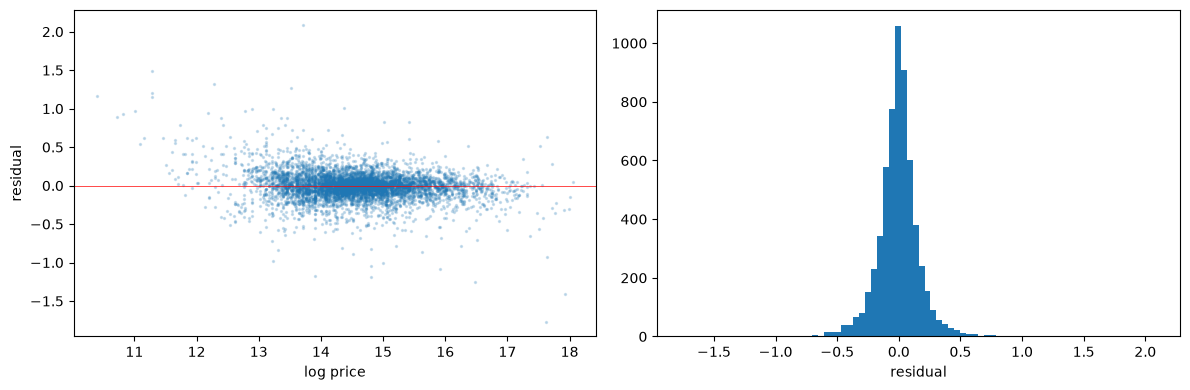

In [7]:
import pandas as pd
# берём сохранённые предсказания из прошлого ноутбука
preds = pd.read_parquet(DATA_RAW.parent / "processed" / "preds_v1.parquet")

# нужны фичи — подтянем из df и сджойним по индексу
df_test = df.loc[y_te.index].reset_index(drop=True)
analysis = pd.concat([df_test, preds], axis=1)

# 1. Ошибки по брендам
brand_err = (analysis
    .groupby("brand")
    .agg(n=("abs_err_rub","size"),
         mae=("abs_err_rub","mean"),
         med_mape=("abs_err_rub", lambda x: x.median()))
    .sort_values("mae", ascending=False)
    .head(20))
print("Худшие бренды по MAE:")
print(brand_err)

# 2. Топ-20 худших предсказаний
worst = analysis.nlargest(20, "abs_err_rub")[
    ["brand","model","year","mileage_km","power_hp","y_true_rub","y_pred_rub","abs_err_rub"]
]
print("\nХудшие предсказания:")
print(worst.to_string(index=False))

# 3. Ошибки по ценовым сегментам
analysis["price_bucket"] = pd.cut(
    analysis["y_true_rub"],
    bins=[0, 500_000, 1_000_000, 2_000_000, 5_000_000, 20_000_000, np.inf],
    labels=["<500k","500k-1M","1-2M","2-5M","5-20M",">20M"]
)
seg = analysis.groupby("price_bucket", observed=True).agg(
    n=("abs_err_rub","size"),
    mae=("abs_err_rub","mean"),
    mape=("abs_err_rub", lambda x: 0),  # посчитай сам
)
seg["mape"] = analysis.groupby("price_bucket", observed=True).apply(
    lambda g: np.mean(np.abs(g["y_true_rub"]-g["y_pred_rub"])/g["y_true_rub"]*100)
)
print("\nОшибки по сегментам:")
print(seg)

# 4. Остатки vs log-цена
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].scatter(analysis["y_true_log"], analysis["y_pred_log"] - analysis["y_true_log"],
              s=2, alpha=0.2)
ax[0].axhline(0, color="red", lw=0.5)
ax[0].set_xlabel("log price"); ax[0].set_ylabel("residual")

ax[1].hist(analysis["y_pred_log"] - analysis["y_true_log"], bins=80)
ax[1].set_xlabel("residual")
plt.tight_layout(); plt.show()

In [8]:
import pandas as pd
import numpy as np
from src.db import DATA_RAW

df = pd.read_parquet(DATA_RAW / "cars.parquet")

# 1. Свежие машины с абсурдными ценами
fresh = df[df["year"] >= 2023].copy()
print(f"year>=2023 всего: {len(fresh)}")

# 2. Сколько из них с ценой > 10M?
high = fresh[fresh["price"] > 10_000_000]
print(f"price>10M среди свежих: {len(high)}")
print(high[["brand","model","year","mileage_km","price"]].head(30))

# 3. Сгруппируй по брендам
print("\nТоп-15 брендов со свежими дорогими:")
print(high.groupby("brand").agg(
    n=("price","size"), min_p=("price","min"), max_p=("price","max"),
    med_mileage=("mileage_km","median")
).sort_values("n", ascending=False).head(15))

# 4. Сколько из них с mileage < 100?
weird = fresh[(fresh["price"] > 10_000_000) & (fresh["mileage_km"] < 100)]
print(f"\nprice>10M И mileage<100: {len(weird)}")
print(weird.groupby("brand").size().sort_values(ascending=False).head(15))

year>=2023 всего: 7871
price>10M среди свежих: 1134
              brand              model  year  mileage_km     price
440             BMW                 X6  2026         7.0  15600000
459   Mercedes-Benz            V-Class  2026        37.0  14750000
553   Mercedes-Benz          GLE-Class  2026        15.0  17480000
595   Mercedes-Benz          GLE-Class  2026         7.0  10614400
694          Toyota       Land Cruiser  2023     33816.0  11450000
716            Tank                700  2026         7.0  11499000
976   Mercedes-Benz          GLS-Class  2025      1900.0  15300000
1050          Dodge         Challenger  2023      5700.0  14500000
1122  Mercedes-Benz            G-Class  2026        20.0  33000000
1245            BMW                 X5  2024         7.0  13600000
1284  Mercedes-Benz          GLE-Class  2026         7.0  11856000
1481        Unknown            Unknown  2026         NaN  11590000
1630            BMW                 X6  2026         7.0  16690000
1704      